# ECS 174 Computer Vision
## Homework 1
### Adam Hetherwick
October 2026

This code is meant to be run on Google Colab for accurate file loading and GPU usage.

Instructions:  For all the following sections, train the model for 50 epochs and plot the curve for loss, training accuracy,
and test accuracy evaluated every epoch. In scenarios where training takes so long, you may decrease total
number of epochs.

### Problem 1

Run the tutorial code out of the box and make sure you get reasonable results. You will report these results in Section 4, so no report needed here.
https://pytorch.org/tutorials/_downloads/cifar10_tutorial.py

In [1]:
# Package import

import torch
import torchvision
import torchvision.transforms as transforms

In [2]:
transform = transforms.Compose(
    [transforms.ToTensor(),                                     # .ToTensor() rearranges dimension to channels x height x width and scale to [0, 1]
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])   # .Normalize() scales to [-1, 1]

In [3]:
from datasets import load_dataset
from torch.utils.data import Dataset

In [4]:
# Import data from local machine to avoid constant redownloading

from google.colab import drive
drive.mount('/content/drive')

import os, shutil

src = '/content/drive/MyDrive/cifar_cache/cifar-10-python.tar.gz'
os.makedirs('./data', exist_ok=True)
shutil.copytree('/content/drive/MyDrive/cifar-10-batches-py',
                './data/cifar-10-batches-py')

Mounted at /content/drive


'./data/cifar-10-batches-py'

In [5]:
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=False, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128,
                                         shuffle=False, num_workers=2)

In [6]:
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

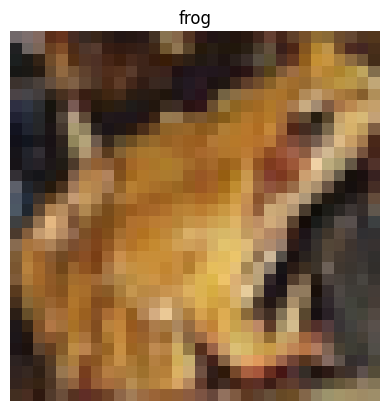

In [7]:
# Visualize images

import matplotlib.pyplot as plt
import numpy as np
import random

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))

i = random.randint(0, len(trainset) - 1)
img, label = trainset[i]
imshow(img)
plt.title(classes[label])
plt.axis('off')
plt.show()

In [8]:
import torch.nn as nn
import torch.nn.functional as F

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [10]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

net = Net()

In [11]:
# Put model on GPU
net = Net().to(device)

In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [13]:
def evaluate(model, loader):
    """Return accuracy (%) of the model on a dataloader."""
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

In [ ]:
from tqdm import tqdm

num_epochs = 50
train_losses, train_accs, test_accs = [], [], []

for epoch in range(num_epochs):
    net.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in tqdm(trainloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(trainloader)
    train_acc = 100 * correct / total
    test_acc = evaluate(net, testloader)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(f'Epoch {epoch + 1}/{num_epochs} | loss: {train_loss:.4f} | '
          f'train acc: {train_acc:.2f}% | test acc: {test_acc:.2f}%')

print('Finished Training')

Epoch 1/50 | loss: 2.3018 | train acc: 10.43% | test acc: 12.52%


Epoch 2/50 | loss: 2.2868 | train acc: 15.52% | test acc: 15.47%


Epoch 3/50 | loss: 2.1880 | train acc: 20.38% | test acc: 25.51%


Epoch 4/50 | loss: 2.0445 | train acc: 27.60% | test acc: 30.01%


Epoch 5/50 | loss: 1.8889 | train acc: 31.64% | test acc: 33.17%


...

Epoch 46/50 | loss: 0.9570 | train acc: 66.44% | test acc: 61.91%


Epoch 47/50 | loss: 0.9530 | train acc: 66.67% | test acc: 62.96%


Epoch 48/50 | loss: 0.9423 | train acc: 67.16% | test acc: 62.16%


Epoch 49/50 | loss: 0.9340 | train acc: 67.25% | test acc: 63.02%


Epoch 50/50 | loss: 0.9250 | train acc: 67.67% | test acc: 61.94%
Finished Training


In [14]:
def run_cnn(net, optimizer, num_epochs: int = 50) -> tuple[list, list, list]:

  from tqdm import tqdm

  train_losses, train_accs, test_accs = [], [], []

  for epoch in range(num_epochs):
      net.train()
      running_loss, correct, total = 0.0, 0, 0

      for inputs, labels in tqdm(trainloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
          inputs, labels = inputs.to(device), labels.to(device)

          optimizer.zero_grad()
          outputs = net(inputs)
          loss = criterion(outputs, labels)
          loss.backward()
          optimizer.step()

          running_loss += loss.item()
          correct += (outputs.argmax(dim=1) == labels).sum().item()
          total += labels.size(0)

      train_loss = running_loss / len(trainloader)
      train_acc = 100 * correct / total
      test_acc = evaluate(net, testloader)

      train_losses.append(train_loss)
      train_accs.append(train_acc)
      test_accs.append(test_acc)

      print(f'Epoch {epoch + 1}/{num_epochs} | loss: {train_loss:.4f} | '
            f'train acc: {train_acc:.2f}% | test acc: {test_acc:.2f}%')

  print('Finished Training')

  return train_losses, train_accs, test_accs

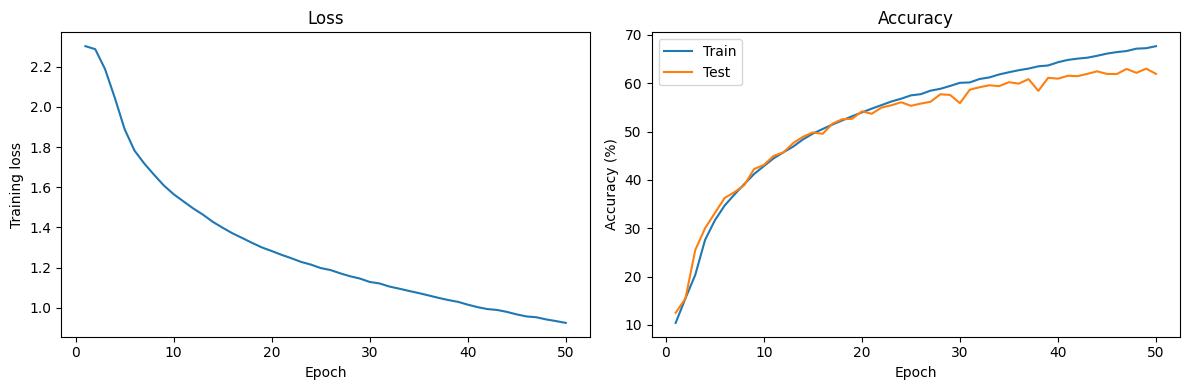

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses)
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accs, label='Train')
plt.plot(epochs, test_accs, label='Test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
import matplotlib.pyplot as plt

def plot_results(train_losses: list, train_accs: list, test_accs: list, num_epochs: int=50) -> None:

  epochs = range(1, num_epochs + 1)

  plt.figure(figsize=(12, 4))

  plt.subplot(1, 2, 1)
  plt.plot(epochs, train_losses)
  plt.xlabel('Epoch')
  plt.ylabel('Training loss')
  plt.title('Loss')

  plt.subplot(1, 2, 2)
  plt.plot(epochs, train_accs, label='Train')
  plt.plot(epochs, test_accs, label='Test')
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy (%)')
  plt.title('Accuracy')
  plt.legend()

  plt.tight_layout()
  plt.show()

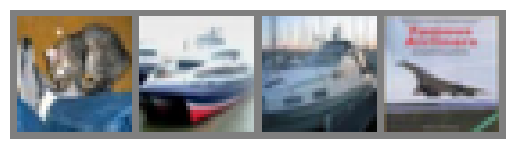

GroundTruth:    cat  ship  ship plane
Predicted:  plane plane plane plane


In [16]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images[:4]))
plt.axis('off')
plt.show()
print('GroundTruth: ', ' '.join('%5s' % classes[labels[j]] for j in range(4)))

outputs = net(images.to(device))
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join('%5s' % classes[predicted[j]] for j in range(4)))

In [17]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        labels = labels.to(device)
        outputs = net(images.to(device))
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

Accuracy of the network on the 10000 test images: 10 %


In [ ]:
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))
with torch.no_grad():
    for data in testloader:
        images, labels = data
        labels = labels.to(device)
        outputs = net(images.to(device))
        _, predicted = torch.max(outputs, 1)
        c = (predicted == labels).squeeze()
        for i in range(4):
            label = labels[i]
            class_correct[label] += c[i].item()
            class_total[label] += 1


for i in range(10):
    print('Accuracy of %5s : %2d %%' % (
        classes[i], 100 * class_correct[i] / class_total[i]))

Accuracy of plane : 75 %
Accuracy of   car : 82 %
Accuracy of  bird : 60 %
Accuracy of   cat : 41 %
Accuracy of  deer : 40 %
Accuracy of   dog : 51 %
Accuracy of  frog : 83 %
Accuracy of horse : 76 %
Accuracy of  ship : 59 %
Accuracy of truck : 61 %


### Problem 2

Change the code to have only a single fully connected layer. The model will have a single layer that
connects the input to the output. What is the number of parameters? In PyTorch, ”nn.Linear” can
be used for fully connected layer.

In [18]:
class Net_2(nn.Module):
    def __init__(self):
        super(Net_2, self).__init__()
        self.fc = nn.Linear(3 * 32 * 32, 10)

    def forward(self, x):
        x = x.view(-1, 3 * 32 * 32)  # flatten each image
        x = self.fc(x)
        return x

net_2 = Net_2()

In [19]:
# Put model on GPU
net_2 = Net_2().to(device)

In [20]:
print(sum(p.numel() for p in net_2.parameters()))

30730


Here we see that there are 3 * 32 * 32 = 30,720 plus 10 biases in the final layer because of the 10 outputs, totaling 30,730.

In [ ]:
optimizer_2 = optim.SGD(net_2.parameters(), lr=0.001, momentum=0.9)  # use the same settings as the original optimizer

train_losses_2, train_accs_2, test_accs_2 = run_cnn(net=net_2, optimizer=optimizer_2, num_epochs=50)

Epoch 1/50 | loss: 1.8822 | train acc: 34.93% | test acc: 39.10%


Epoch 2/50 | loss: 1.7806 | train acc: 39.67% | test acc: 39.19%


Epoch 3/50 | loss: 1.7505 | train acc: 40.35% | test acc: 39.80%


Epoch 4/50 | loss: 1.7324 | train acc: 41.19% | test acc: 40.69%


Epoch 5/50 | loss: 1.7190 | train acc: 41.47% | test acc: 40.63%


...

Epoch 46/50 | loss: 1.6268 | train acc: 44.96% | test acc: 41.15%


Epoch 47/50 | loss: 1.6258 | train acc: 45.03% | test acc: 40.41%


Epoch 48/50 | loss: 1.6255 | train acc: 45.14% | test acc: 40.47%


Epoch 49/50 | loss: 1.6250 | train acc: 45.14% | test acc: 41.08%


Epoch 50/50 | loss: 1.6242 | train acc: 45.07% | test acc: 41.22%
Finished Training


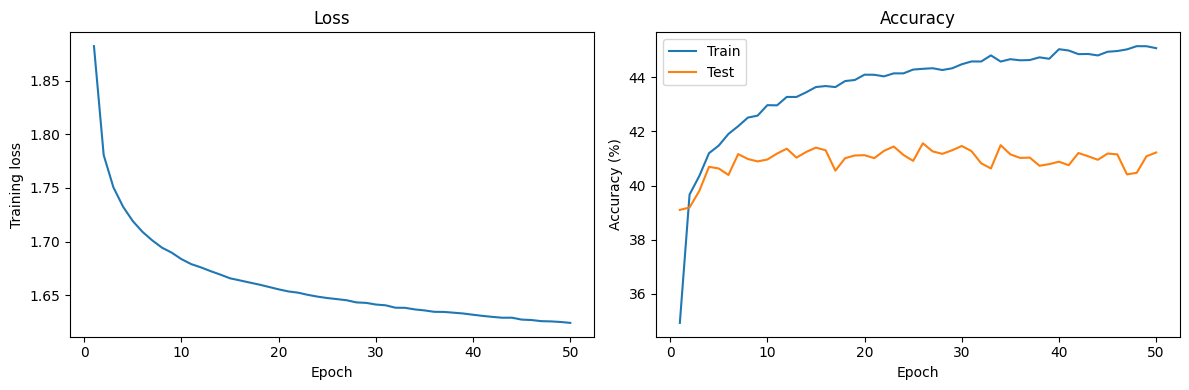

In [ ]:
plot_results(train_losses_2, train_accs_2, test_accs_2, num_epochs=50)

### Problem 3

Change the code to have multiple fully connected layers. Try having a layer from input to 110 neurons
and then a layer to 74 neurons, and finally a layer to 10 neurons, one for each category. What happens
if you do not use ReLU? Describe why.

In [21]:
class Net_3(nn.Module):
    def __init__(self):
        super(Net_3, self).__init__()
        self.fc1 = nn.Linear(3 * 32 * 32, 110)
        self.fc2 = nn.Linear(110, 74)
        self.fc3 = nn.Linear(74, 10)

    def forward(self, x):
        x = x.view(-1, 3 * 32 * 32)  # flatten each image
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)              # no ReLU on the output (raw class scores)
        return x

In [22]:
net_3 = Net_3().to(device)
optimizer_3 = optim.SGD(net_3.parameters(), lr=0.001, momentum=0.9)

In [ ]:
train_losses_3, train_accs_3, test_accs_3 = run_cnn(net=net_3, optimizer=optimizer_3, num_epochs=50)

Epoch 1/50 | loss: 2.0233 | train acc: 29.15% | test acc: 35.02%


Epoch 2/50 | loss: 1.8523 | train acc: 35.97% | test acc: 37.00%


Epoch 3/50 | loss: 1.8010 | train acc: 37.81% | test acc: 38.53%


Epoch 4/50 | loss: 1.7705 | train acc: 39.06% | test acc: 39.00%


Epoch 5/50 | loss: 1.7493 | train acc: 39.86% | test acc: 40.29%


...

Epoch 46/50 | loss: 1.6291 | train acc: 44.77% | test acc: 40.50%


Epoch 47/50 | loss: 1.6289 | train acc: 44.75% | test acc: 40.76%


Epoch 48/50 | loss: 1.6286 | train acc: 44.74% | test acc: 41.06%


Epoch 49/50 | loss: 1.6267 | train acc: 44.82% | test acc: 40.53%


Epoch 50/50 | loss: 1.6267 | train acc: 44.83% | test acc: 40.35%
Finished Training


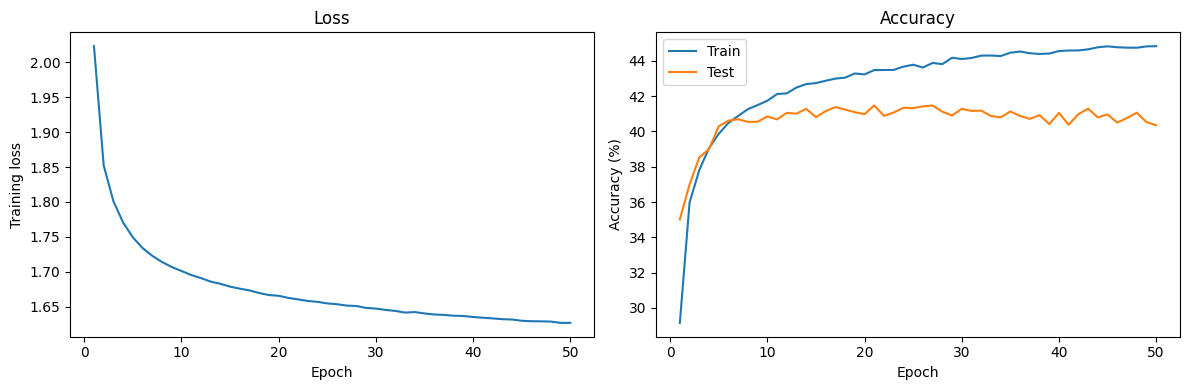

In [ ]:
plot_results(train_losses_3, train_accs_3, test_accs_3, num_epochs=50)

Without ReLU activation function, any multi-layer neural network is just a linear combination of each layer which can be represented by a vector. This is why the results are comparable to the 2 layer neural network in problem 2.

### Problem 4

Change the code by adding two convolutional layers along with maxpooling layers before the fully
connected layers. This will be similar to the example in the tutorial. Use this model for the following
sections.

In [23]:
class Net_4(nn.Module):
    def __init__(self):
        super(Net_4, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 110)
        self.fc2 = nn.Linear(110, 74)
        self.fc3 = nn.Linear(74, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [24]:
net_4 = Net_4().to(device)
optimizer_4 = optim.SGD(net_4.parameters(), lr=0.001, momentum=0.9)  # match the earlier settings

In [ ]:
train_losses_4, train_accs_4, test_accs_4 = run_cnn(net=net_4, optimizer=optimizer_4, num_epochs=50)

Epoch 1/50 | loss: 2.3009 | train acc: 11.44% | test acc: 11.77%


Epoch 2/50 | loss: 2.2835 | train acc: 14.20% | test acc: 18.10%


Epoch 3/50 | loss: 2.1826 | train acc: 21.31% | test acc: 25.89%


Epoch 4/50 | loss: 2.0759 | train acc: 26.96% | test acc: 30.00%


Epoch 5/50 | loss: 1.9776 | train acc: 30.67% | test acc: 33.37%


...

Epoch 46/50 | loss: 0.9191 | train acc: 67.68% | test acc: 63.40%


Epoch 47/50 | loss: 0.9129 | train acc: 67.96% | test acc: 63.78%


Epoch 48/50 | loss: 0.9065 | train acc: 67.99% | test acc: 64.13%


Epoch 49/50 | loss: 0.8955 | train acc: 68.55% | test acc: 63.66%


Epoch 50/50 | loss: 0.8879 | train acc: 68.95% | test acc: 64.68%
Finished Training


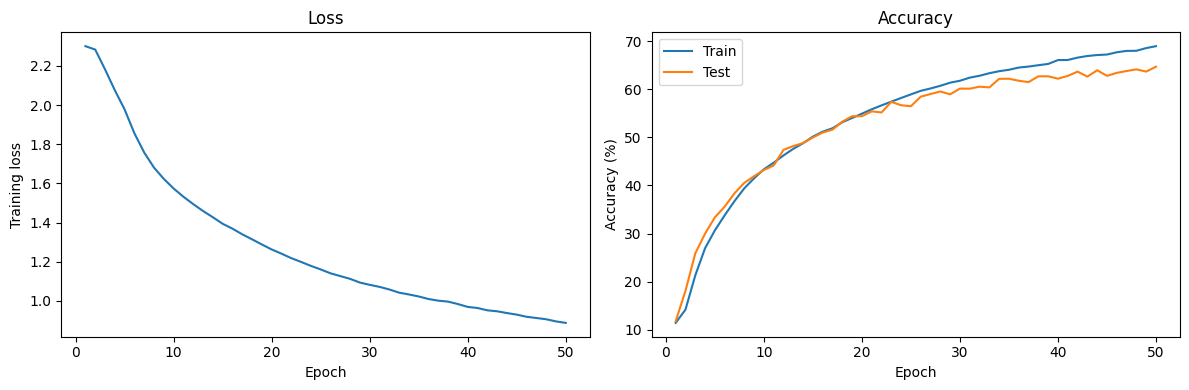

In [ ]:
plot_results(train_losses_4, train_accs_4, test_accs_4, num_epochs=50)

Here we see the train and test accuracy both increase back up to levels seen in problem 1. The max pooling and convolution layers prove their clear need and easily out preform single layer neural networks and its equivalent multilayered neural network with no activation function.

The slight difference in test and training accuracies between this CNN and the CNN in problem 1 is due to different layer widths and initialization randomness.

### Problem 5

Try multiple batch sizes to see the effect and describe the findings. Please use batch size of 1, 4, and
1000. If 1000 does not fit into the memory of your machine, please feel free to reduce it to the largest
possible number.

In [25]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

In [26]:
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

In [27]:
def run_experiment(batch_size, num_epochs, lr=0.001, momentum=0.9):
    trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                              shuffle=True, num_workers=2, pin_memory=True)
    testloader = torch.utils.data.DataLoader(testset, batch_size=1000,
                                             shuffle=False, num_workers=2, pin_memory=True)

    net = Net_4().to(device)                      # fresh model for every run
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    hist = {'loss': [], 'train_acc': [], 'test_acc': [], 'time': []}
    start = time.time()

    for epoch in range(num_epochs):
        net.train()
        running_loss, correct, total = 0.0, 0, 0

        for inputs, labels in tqdm(trainloader, desc=f'bs={batch_size} epoch {epoch + 1}/{num_epochs}', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        hist['loss'].append(running_loss / len(trainloader))
        hist['train_acc'].append(100 * correct / total)
        hist['test_acc'].append(evaluate(net, testloader))
        hist['time'].append(time.time() - start)

        print(f'bs={batch_size} | epoch {epoch + 1}/{num_epochs} | loss: {hist["loss"][-1]:.4f} | '
              f'train acc: {hist["train_acc"][-1]:.2f}% | test acc: {hist["test_acc"][-1]:.2f}% | '
              f'elapsed: {hist["time"][-1]:.0f}s')

    return hist

In [ ]:
results = {}
for bs in [1000, 4, 1]:
    results[bs] = run_experiment(bs, num_epochs=10)

bs=1000 | epoch 1/10 | loss: 2.3037 | train acc: 10.00% | test acc: 9.99% | elapsed: 14s


bs=1000 | epoch 2/10 | loss: 2.3030 | train acc: 10.00% | test acc: 10.02% | elapsed: 27s


bs=1000 | epoch 3/10 | loss: 2.3023 | train acc: 10.05% | test acc: 10.05% | elapsed: 40s


bs=1000 | epoch 4/10 | loss: 2.3016 | train acc: 10.15% | test acc: 10.17% | elapsed: 53s


bs=1000 | epoch 5/10 | loss: 2.3009 | train acc: 10.28% | test acc: 10.18% | elapsed: 67s


...

bs=1 | epoch 6/10 | loss: 1.4396 | train acc: 51.15% | test acc: 50.22% | elapsed: 1212s


bs=1 | epoch 7/10 | loss: 1.4451 | train acc: 51.00% | test acc: 52.16% | elapsed: 1415s


bs=1 | epoch 8/10 | loss: 1.4562 | train acc: 50.86% | test acc: 50.56% | elapsed: 1617s


bs=1 | epoch 9/10 | loss: 1.4736 | train acc: 50.50% | test acc: 47.10% | elapsed: 1817s


bs=1 | epoch 10/10 | loss: 1.4896 | train acc: 50.05% | test acc: 46.64% | elapsed: 2019s


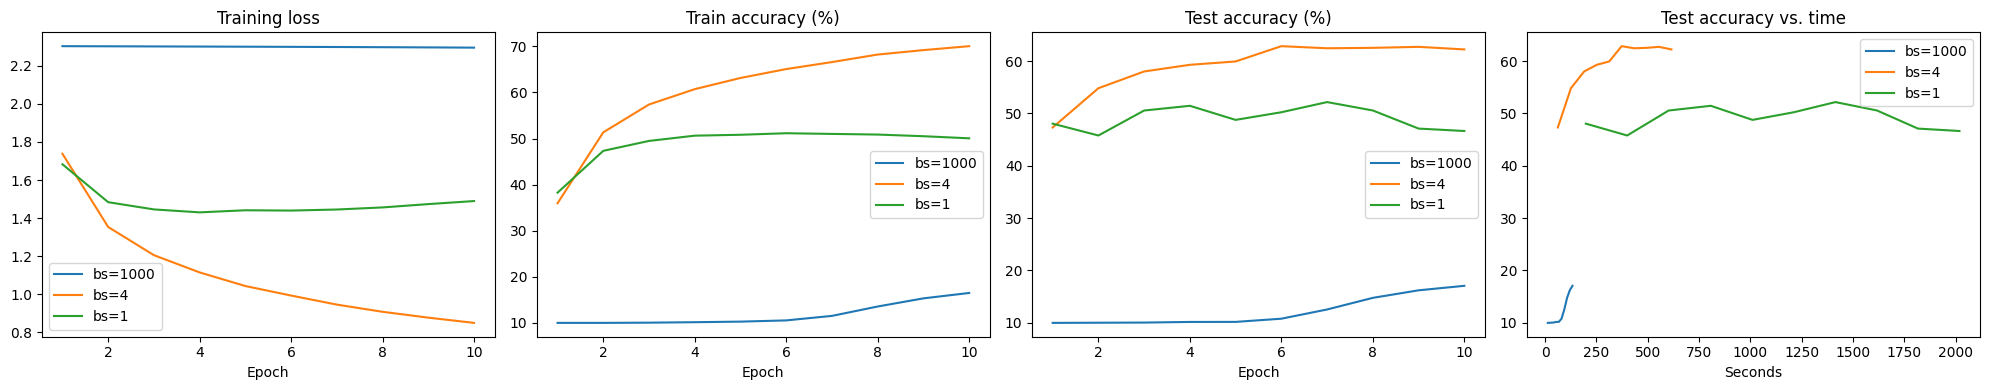

bs=1000 | final test acc: 17.07% | total time: 134s | avg time/epoch: 13s
bs=   4 | final test acc: 62.22% | total time: 616s | avg time/epoch: 62s
bs=   1 | final test acc: 46.64% | total time: 2019s | avg time/epoch: 202s


In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for bs, h in results.items():
    ep = range(1, len(h['loss']) + 1)
    ax[0].plot(ep, h['loss'], label=f'bs={bs}')
    ax[1].plot(ep, h['train_acc'], label=f'bs={bs}')
    ax[2].plot(ep, h['test_acc'], label=f'bs={bs}')
    ax[3].plot(h['time'], h['test_acc'], label=f'bs={bs}')

for a, t, x in zip(ax, ['Training loss', 'Train accuracy (%)', 'Test accuracy (%)', 'Test accuracy vs. time'],
                   ['Epoch', 'Epoch', 'Epoch', 'Seconds']):
    a.set_title(t); a.set_xlabel(x); a.legend()
plt.tight_layout()
plt.show()

for bs, h in results.items():
    print(f'bs={bs:>4} | final test acc: {h["test_acc"][-1]:.2f}% | total time: {h["time"][-1]:.0f}s | '
          f'avg time/epoch: {h["time"][-1] / len(h["time"]):.0f}s')

The training loss for batch size=1000 does not change much, potentially because with such a large batch size, each iteration through the forward and backward pass does not update the weights much. We see for batch size=1 it has minor improvements however for a reasonable choice like 4, it decreases after 10 epochs.

The train accuracy plot is similar to a vertically flipped training loss plot. I notice for the large batch size, accuracy does not increase much because each iteration yields very small update weights. Batch size = 1 shows some improvement on weights after each epoch but plateaus, while 4 shows a clear upward trend.

Test accuracy follows a similar pattern with train accuracy, with some slight variations. Once again batch size = 4 performs the best.

It is worth noting that batch size = 1 has the longest run time because with 1 training point, it is forcing a forward and backward pass once for each training point, thus 50,000 steps. Far larger than if we chose 4 or 1000.

### Problem 6

Try multiple learning rates to see the effect and describe the findings. Please use learning rates of 10,
0.1, 0.01, and 0.001.

In [ ]:
BATCH_SIZE = 128
NUM_EPOCHS = 50

lr_results = {}
for lr in [10, 0.1, 0.01, 0.001]:
    print(f'\n===== lr = {lr} =====')
    lr_results[lr] = run_experiment(BATCH_SIZE, num_epochs=NUM_EPOCHS, lr=lr)


===== lr = 10 =====


bs=128 epoch 1/50:   0%|          | 0/391 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


bs=128 | epoch 1/50 | loss: 2.5578 | train acc: 10.11% | test acc: 10.00% | elapsed: 26s


bs=128 | epoch 2/50 | loss: 2.7112 | train acc: 10.08% | test acc: 10.00% | elapsed: 61s


bs=128 | epoch 3/50 | loss: 2.6436 | train acc: 9.73% | test acc: 10.00% | elapsed: 101s


...

bs=128 | epoch 46/50 | loss: 0.9657 | train acc: 65.91% | test acc: 61.45% | elapsed: 1306s


bs=128 | epoch 47/50 | loss: 0.9582 | train acc: 66.26% | test acc: 61.99% | elapsed: 1335s


bs=128 | epoch 48/50 | loss: 0.9491 | train acc: 66.50% | test acc: 62.47% | elapsed: 1362s


bs=128 | epoch 49/50 | loss: 0.9440 | train acc: 66.75% | test acc: 62.12% | elapsed: 1390s


bs=128 | epoch 50/50 | loss: 0.9321 | train acc: 67.14% | test acc: 62.19% | elapsed: 1419s


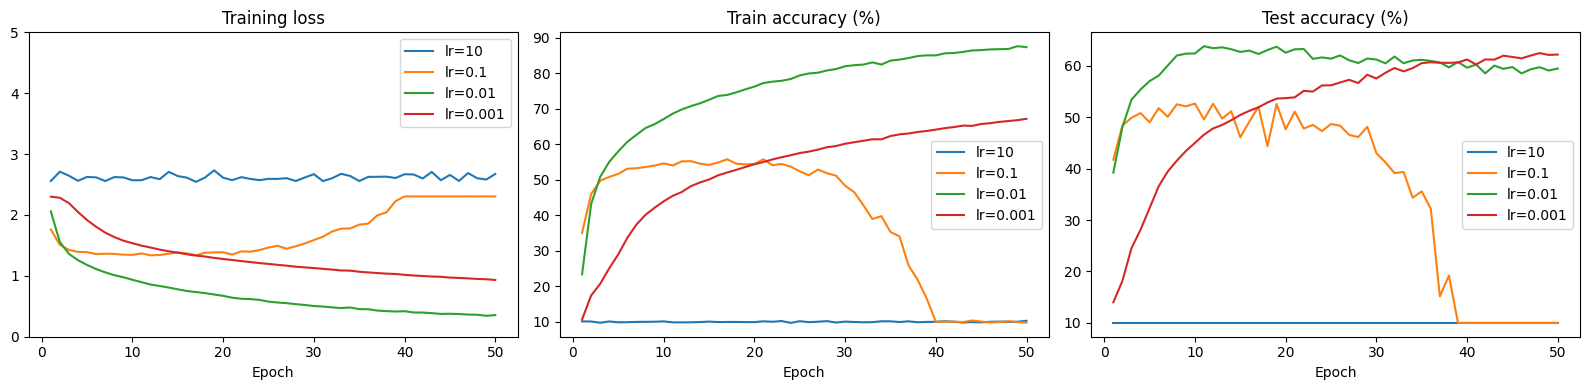

lr=10     | final loss: 2.6736 | final train acc: 10.29% | final test acc: 10.00% | best test acc: 10.00%
lr=0.1    | final loss: 2.3043 | final train acc: 9.79% | final test acc: 10.00% | best test acc: 52.65%
lr=0.01   | final loss: 0.3548 | final train acc: 87.29% | final test acc: 59.47% | best test acc: 63.82%
lr=0.001  | final loss: 0.9321 | final train acc: 67.14% | final test acc: 62.19% | best test acc: 62.47%


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for lr, h in lr_results.items():
    ep = range(1, len(h['loss']) + 1)
    ax[0].plot(ep, h['loss'], label=f'lr={lr}')
    ax[1].plot(ep, h['train_acc'], label=f'lr={lr}')
    ax[2].plot(ep, h['test_acc'], label=f'lr={lr}')

ax[0].set_title('Training loss');       ax[0].set_ylim(0, 5)   # lr=10 can explode, so clip the axis
ax[1].set_title('Train accuracy (%)')
ax[2].set_title('Test accuracy (%)')
for a in ax:
    a.set_xlabel('Epoch'); a.legend()
plt.tight_layout()
plt.show()

for lr, h in lr_results.items():
    print(f'lr={lr:<6} | final loss: {h["loss"][-1]:.4f} | final train acc: {h["train_acc"][-1]:.2f}% | '
          f'final test acc: {h["test_acc"][-1]:.2f}% | best test acc: {max(h["test_acc"]):.2f}%')

Here we see staggering performances from larger learning rates on the training loss, with a reasonable step size for gradient descent and back propagation being about 0.01. This holds for training and test accuracy as well, since the lr=0.01 outperforms others quite easily.

### Problem 7

Please add some data augmentation to avoid overfitting. Note that you need to do this only for the
trainnig and not the testing. You may use line 244-260 from Imagenet sample code:

https://github.com/pytorch/examples/blob/master/imagenet/main.py

In [28]:
normalize = transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),   # CIFAR version of random crop
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    normalize,
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    normalize,
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=False, transform=train_transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=False, transform=test_transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

In [29]:
net_4 = Net_4().to(device)
optimizer_4 = optim.SGD(net_4.parameters(), lr=0.01, momentum=0.9)

In [ ]:
train_losses_7, train_accs_7, test_accs_7 = run_cnn(net=net_4, optimizer=optimizer_4, num_epochs=50)

Epoch 1/50:   0%|          | 0/391 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 1/50 | loss: 2.0925 | train acc: 21.46% | test acc: 35.88%


Epoch 2/50 | loss: 1.7053 | train acc: 36.52% | test acc: 44.36%


Epoch 3/50 | loss: 1.5592 | train acc: 42.56% | test acc: 48.72%


Epoch 4/50 | loss: 1.4707 | train acc: 46.31% | test acc: 50.47%


...

Epoch 46/50 | loss: 0.9123 | train acc: 67.76% | test acc: 68.35%


Epoch 47/50 | loss: 0.9102 | train acc: 67.98% | test acc: 69.61%


Epoch 48/50 | loss: 0.9126 | train acc: 67.77% | test acc: 68.88%


Epoch 49/50 | loss: 0.9070 | train acc: 67.95% | test acc: 69.74%


Epoch 50/50 | loss: 0.9009 | train acc: 68.41% | test acc: 69.31%
Finished Training


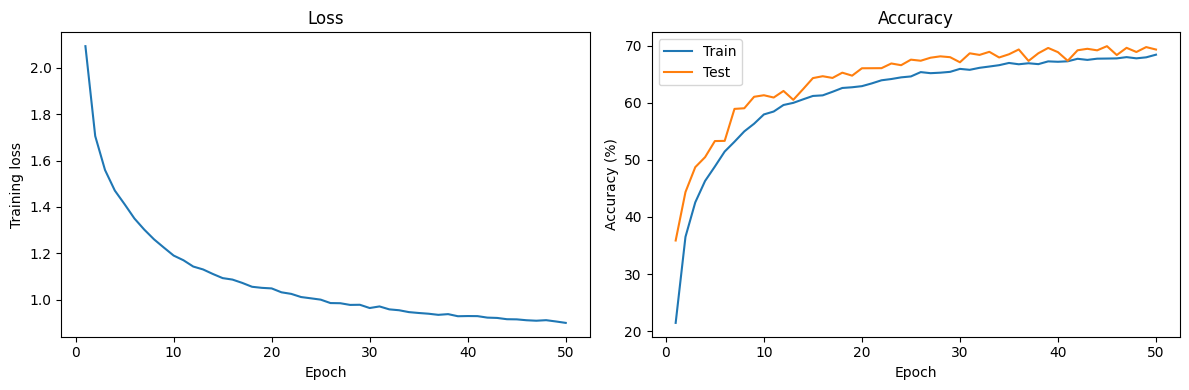

In [ ]:
plot_results(train_losses_7, train_accs_7, test_accs_7, num_epochs=50)

The results here look very similar to that of problem 4, with the only difference being the learning rate adjusted from lr=0.001 to 0.01, along with the obvious data augmentation bit that adds a length 4 padding on each side to permit a random crop, along with a random horizontal flip. The results show similar loss pattern and slightly higher test performance than the training set. The data augmentation prevents overfitting and suplements sample size.

### Problem 8

Change the loss function from Cross Entropy to Mean Squared Error and report the effect.

In [30]:
import torch.nn.functional as F

class MSEOneHot(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.mse = nn.MSELoss()
        self.num_classes = num_classes

    def forward(self, outputs, labels):
        targets = F.one_hot(labels, self.num_classes).float()
        return self.mse(outputs, targets)

criterion = MSEOneHot()

In [ ]:
net_4 = Net_4().to(device)
optimizer_4 = optim.SGD(net_4.parameters(), lr=0.01, momentum=0.9)

train_losses_8, train_accs_8, test_accs_8 = run_cnn(net=net_4, optimizer=optimizer_4, num_epochs=50)

Epoch 1/50 | loss: 0.0905 | train acc: 14.84% | test acc: 19.57%


Epoch 2/50 | loss: 0.0877 | train acc: 18.64% | test acc: 20.37%


Epoch 3/50 | loss: 0.0860 | train acc: 20.53% | test acc: 23.55%


Epoch 4/50 | loss: 0.0852 | train acc: 22.38% | test acc: 25.55%


Epoch 5/50 | loss: 0.0843 | train acc: 24.46% | test acc: 28.38%


...

Epoch 46/50 | loss: 0.0629 | train acc: 52.81% | test acc: 56.11%


Epoch 47/50 | loss: 0.0625 | train acc: 53.34% | test acc: 56.69%


Epoch 48/50 | loss: 0.0622 | train acc: 53.36% | test acc: 56.41%


Epoch 49/50 | loss: 0.0619 | train acc: 53.70% | test acc: 57.33%


Epoch 50/50 | loss: 0.0618 | train acc: 54.06% | test acc: 57.22%
Finished Training


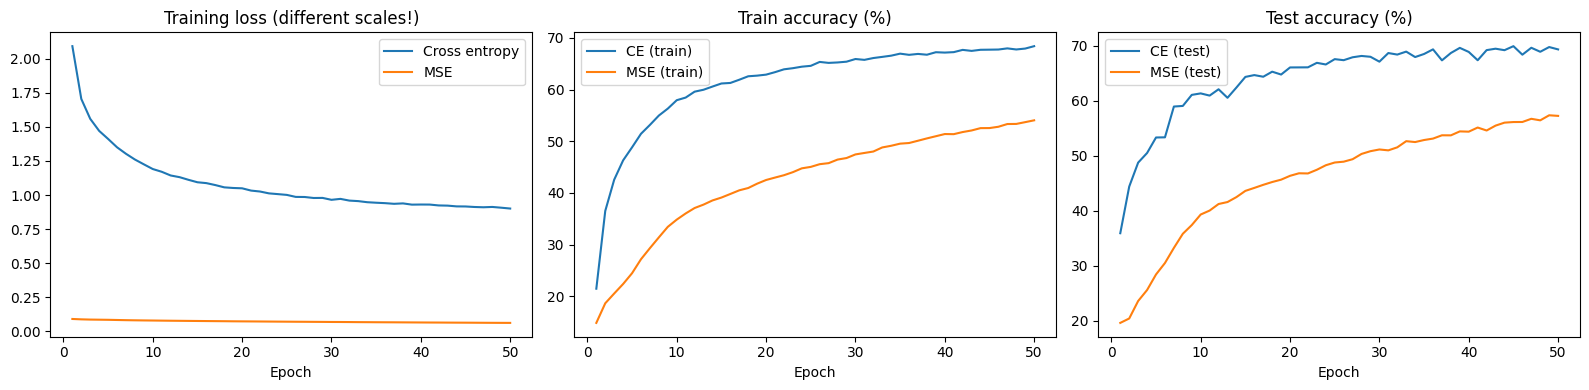

CE  | final train: 68.41% | final test: 69.31%
MSE | final train: 54.06% | final test: 57.22%


In [ ]:
epochs = range(1, 51)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(epochs, train_losses_7, label='Cross entropy')
ax[0].plot(epochs, train_losses_8, label='MSE')
ax[0].set_title('Training loss (different scales!)')

ax[1].plot(epochs, train_accs_7, label='CE (train)')
ax[1].plot(epochs, train_accs_8, label='MSE (train)')
ax[1].set_title('Train accuracy (%)')

ax[2].plot(epochs, test_accs_7, label='CE (test)')
ax[2].plot(epochs, test_accs_8, label='MSE (test)')
ax[2].set_title('Test accuracy (%)')

for a in ax:
    a.set_xlabel('Epoch'); a.legend()
plt.tight_layout()
plt.show()

print(f'CE  | final train: {train_accs_7[-1]:.2f}% | final test: {test_accs_7[-1]:.2f}%')
print(f'MSE | final train: {train_accs_8[-1]:.2f}% | final test: {test_accs_8[-1]:.2f}%')

The train and test accuracy plots clearly expose MSE as an unsuitable loss funcion when the response variable is discrete (car, truck, frog etc). It is essentially the 2-norm of (predicted - true)^2. MSE imposes a slower learning rate in gradient descent and forfeits a lower accuracy ceiling.

Cross-entropy penalizes loss on a different scale, particularly: loss = -log(p_correct), which gives gradient descent the push it needs to flourish.